In [12]:
import pandas as pd

df = pd.read_csv("AI_Human.csv")
df.head()

,text,generated
0,Cars. Cars have been around since they became ...,0.0
1,Transportation is a large necessity in most co...,0.0
2,"""America's love affair with it's vehicles seem...",0.0
3,How often do you ride in a car? Do you drive a...,0.0
4,Cars are a wonderful thing. They are perhaps o...,0.0


In [13]:
ai_written=df[df["generated"]== 1].sample(5000, random_state=42)
human_written = df[df["generated"] == 0].sample(5000, random_state=42)

balanced_dataset=pd.concat([ai_written, human_written]).sample(frac=1,random_state=42)

print(balanced_dataset["generated"].value_counts())
print(balanced_dataset.head())

generated
0.0    5000
1.0    5000
Name: count, dtype: int64
                                                     text  generated
269265  Dear Principal,\n\nWe have been hearing quite ...        0.0
327273   Dear [State Senator],\n\nI am writing to expr...        1.0
167398  As high school students, we are constantly bom...        1.0
291678  Hi, I'm a 6th garden and I think zoos ANE Near...        1.0
457139  Sure, jar's my attempt at writing an essay as ...        1.0


In [14]:
balanced_dataset.head()

,text,generated
269265,"Dear Principal,\n\nWe have been hearing quite ...",0.0
327273,"Dear [State Senator],\n\nI am writing to expr...",1.0
167398,"As high school students, we are constantly bom...",1.0
291678,"Hi, I'm a 6th garden and I think zoos ANE Near...",1.0
457139,"Sure, jar's my attempt at writing an essay as ...",1.0


In [15]:
#Train/Test Split

from sklearn.model_selection import train_test_split

X=balanced_dataset["text"]
y=balanced_dataset["generated"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

In [16]:
#Feature Extraction using text statistics

import numpy as np

def text_extraction(text_statistics):
    new_features=[]
    for text in text_statistics:
        if type(text)== str:
            word=text.split()
            nr_words=len(word)
            nr_chars=len(text)
            unique_words=len(set(word))
            if nr_words:
                avg_word_length=nr_chars/nr_words
            else: 
                avg_word_length=0
            if nr_chars:
                punctuation_ratio= sum(char in".,;:!?'" for char in text) / nr_chars
            else:
                punctuation_ratio=0
            if nr_chars:
                capital_ratio= sum(char.isupper() for char in text) / nr_chars
            else:
                capital_ratio=0
            if nr_chars:
                digit_ratio= sum(char.isdigit() for char in text) / nr_chars
            else:
                digit_ratio=0   
            if nr_words:
                type_token_r=unique_words/nr_words
            else:    
                type_token_r=0

            new_features.append ([nr_words, nr_chars, avg_word_length, punctuation_ratio, capital_ratio, digit_ratio, type_token_r])  

    return np.array(new_features) 

X_train_new_f=text_extraction(X_train)
X_test_new_f=text_extraction(X_test)

In [17]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Define TfidfVectorizer
tfidf = TfidfVectorizer(
    max_features=20000,   
    ngram_range=(1, 2),     
    lowercase=True,
    stop_words='english'      
)

# train the vectorizer on the training set and transform it
X_train_tfidf = tfidf.fit_transform(X_train)

# Transform the test set 
X_test_tfidf = tfidf.transform(X_test)

print(X_train_tfidf.shape)
print(X_test_tfidf.shape)

(8000, 20000)
(2000, 20000)


k=1, accuracy=0.8410
k=2, accuracy=0.8340
k=3, accuracy=0.8465
k=4, accuracy=0.8460
k=5, accuracy=0.8575
k=6, accuracy=0.8500
k=7, accuracy=0.8580
k=8, accuracy=0.8585
k=9, accuracy=0.8630
k=10, accuracy=0.8600
k=11, accuracy=0.8630
k=12, accuracy=0.8645
k=13, accuracy=0.8640
k=14, accuracy=0.8650
k=15, accuracy=0.8645
k=16, accuracy=0.8695
k=17, accuracy=0.8650
k=18, accuracy=0.8685
k=19, accuracy=0.8680
k=20, accuracy=0.8700
k=21, accuracy=0.8705
k=22, accuracy=0.8660
k=23, accuracy=0.8685
k=24, accuracy=0.8670
k=25, accuracy=0.8650
k=26, accuracy=0.8700
k=27, accuracy=0.8695
k=28, accuracy=0.8680
k=29, accuracy=0.8700
best k = 21 , best accuracy = 0.8705
Accuracy: 0.8705


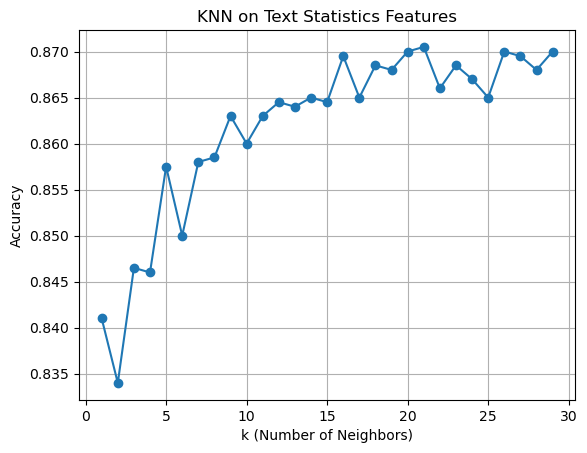

In [7]:
import matplotlib.pyplot as plt



from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_new_f)
X_test_scaled = scaler.transform(X_test_new_f)





# KNN on statistical features

from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix


k_values = range(1, 30)

# save results 
knn_acc_stats = []

# use for loop to find the best k value 
for k in k_values:
    knn_stats = KNeighborsClassifier(n_neighbors=k)
    knn_stats.fit(X_train_scaled, y_train)
    y_pred_stats = knn_stats.predict(X_test_scaled)
    acc = accuracy_score(y_test, y_pred_stats)
    knn_acc_stats.append(acc)
    print(f"k={k}, accuracy={acc:.4f}")

best_k_stats = k_values[knn_acc_stats.index(max(knn_acc_stats))]
print("best k =", best_k_stats, ", best accuracy =", max(knn_acc_stats))


# initialize KNN using the best k 
knn_stats_best = KNeighborsClassifier(n_neighbors=best_k_stats)
knn_stats_best.fit(X_train_scaled, y_train)
y_pred_stats_best = knn_stats_best.predict(X_test_scaled)


print("Accuracy:", accuracy_score(y_test, y_pred_stats_best))


# plot KNN on statistical features

plt.figure()
plt.plot(k_values, knn_acc_stats, marker = 'o')
plt.xlabel("k (Number of Neighbors)")
plt.ylabel("Accuracy")
plt.title("KNN on Text Statistics Features")
plt.grid(True)
plt.show()

k=1, accuracy=0.8995
k=2, accuracy=0.8965
k=3, accuracy=0.9020
k=4, accuracy=0.9035
k=5, accuracy=0.9100
k=6, accuracy=0.9130
k=7, accuracy=0.9155
k=8, accuracy=0.9160
k=9, accuracy=0.9165
k=10, accuracy=0.9190
k=11, accuracy=0.9215
k=12, accuracy=0.9235
k=13, accuracy=0.9240
k=14, accuracy=0.9255
k=15, accuracy=0.9245
k=16, accuracy=0.9280
k=17, accuracy=0.9250
k=18, accuracy=0.9260
k=19, accuracy=0.9285
k=20, accuracy=0.9280
k=21, accuracy=0.9265
k=22, accuracy=0.9260
k=23, accuracy=0.9300
k=24, accuracy=0.9265
k=25, accuracy=0.9280
k=26, accuracy=0.9260
k=27, accuracy=0.9265
k=28, accuracy=0.9240
k=29, accuracy=0.9255
best k = 23 , best accuracy = 0.93
Accuracy 0.93


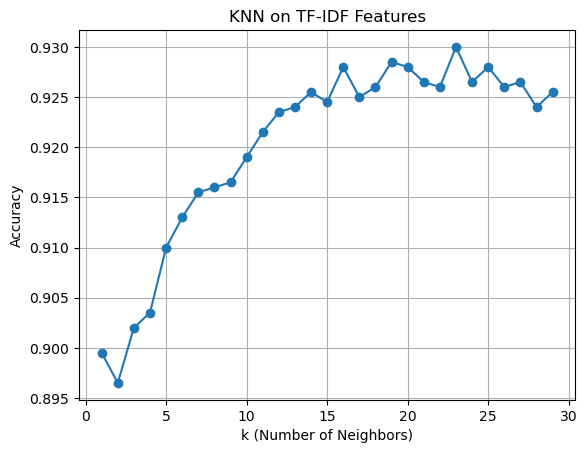

In [8]:


# KNN on TF-IDF features


# save results 
knn_acc_tfidf = []

# use for loop to find the best k value 
for k in k_values:
    knn_tfidf = KNeighborsClassifier(
        n_neighbors=k
    )
    knn_tfidf.fit(X_train_tfidf, y_train)
    y_pred_tfidf = knn_tfidf.predict(X_test_tfidf)
    acc = accuracy_score(y_test, y_pred_tfidf)
    knn_acc_tfidf.append(acc)
    print(f"k={k}, accuracy={acc:.4f}")

best_k_tfidf = k_values[knn_acc_tfidf.index(max(knn_acc_tfidf))]
print("best k =", best_k_tfidf, ", best accuracy =", max(knn_acc_tfidf))


knn_tfidf_best = KNeighborsClassifier(
    n_neighbors=best_k_tfidf
)
knn_tfidf_best.fit(X_train_tfidf, y_train)
y_pred_tfidf_best = knn_tfidf_best.predict(X_test_tfidf)


print("Accuracy", accuracy_score(y_test, y_pred_tfidf_best))


# plot KNN on TF-IDF

plt.figure()
plt.plot(k_values, knn_acc_tfidf, marker='o')
plt.xlabel("k (Number of Neighbors)")
plt.ylabel("Accuracy")
plt.title("KNN on TF-IDF Features")
plt.grid(True)
plt.show()

In [9]:
from sklearn.neural_network import MLPClassifier

# Define different MLP neural networks
mlp_structures = [
    (16,),
    (32,),
    (64,),
    (128,),
    (32, 16),
    (64, 32),
    (128, 64),
    (128, 64, 32),
    (256, 128, 64),
]

# save results
results = []



for structure in mlp_structures:

    print(f"Start training structure: {structure} ...")

    # use 7 statistical features
    mlp_raw = MLPClassifier(
        hidden_layer_sizes= structure,
        activation ='relu',
        max_iter = 500,
        random_state = 42
    )

    mlp_raw.fit(X_train_scaled, y_train)
    prediction_raw = mlp_raw.predict(X_test_scaled)
    accuracy_raw =  accuracy_score(y_test, prediction_raw)

    print(f"Raw features accuracy: {accuracy_raw:.4f}")
    results.append((structure, accuracy_raw))



print("Summary of resaults")
for structure, accuracy_raw in results:
    print(f"structure: {structure}\taccuracy_raw: {accuracy_raw:.4f}")

Start training structure: (16,) ...
Raw features accuracy: 0.8770
Start training structure: (32,) ...
Raw features accuracy: 0.8840
Start training structure: (64,) ...
Raw features accuracy: 0.8870
Start training structure: (128,) ...
Raw features accuracy: 0.8880
Start training structure: (32, 16) ...
Raw features accuracy: 0.8785
Start training structure: (64, 32) ...
Raw features accuracy: 0.8765
Start training structure: (128, 64) ...
Raw features accuracy: 0.8730
Start training structure: (128, 64, 32) ...
Raw features accuracy: 0.8620
Start training structure: (256, 128, 64) ...
Raw features accuracy: 0.8630
Summary of resaults
structure: (16,)	accuracy_raw: 0.8770
structure: (32,)	accuracy_raw: 0.8840
structure: (64,)	accuracy_raw: 0.8870
structure: (128,)	accuracy_raw: 0.8880
structure: (32, 16)	accuracy_raw: 0.8785
structure: (64, 32)	accuracy_raw: 0.8765
structure: (128, 64)	accuracy_raw: 0.8730
structure: (128, 64, 32)	accuracy_raw: 0.8620
structure: (256, 128, 64)	accuracy_

#### We used different structures of MLP. One structure with one hidden layer containing 32 neurons was already good, but the best result came from using one hidden layer with 128 neurons with accuracy about 0.8880.

In [10]:
from itertools import product

# Define different MLP neural networks
mlp_structures = [
    (16,),
    (32,),
    (64,),
    (128,),
    (32, 16),
    (64, 32),
    (128, 64),
    (128, 64, 32),
    (256, 128, 64),
]

activations = ['relu', 'tanh', 'logistic']
batch_sizes = [32, 64, 128]

results = []

for structure, activation, batch in product(mlp_structures, activations, batch_sizes):
    print(f"Training: structure = {structure}, activation = {activation}, batch_size = {batch} ...")

    mlp = MLPClassifier(
        hidden_layer_sizes=structure,
        activation=activation,
        batch_size=batch,
        max_iter=500,
        random_state=42
    )

    mlp.fit(X_train_scaled, y_train)
    pred = mlp.predict(X_test_scaled)
    accuracy = accuracy_score(y_test, pred)

    print(f"Accuracy: {accuracy:.4f}\n")
    results.append((structure, activation, batch, accuracy))


for structure, activation, batch, accuracy in results:
    print(f"structure = {structure}, activation = {activation}, batch = {batch} -> accuracy = {accuracy:.4f}")


Training: structure = (16,), activation = relu, batch_size = 32 ...
Accuracy: 0.8775

Training: structure = (16,), activation = relu, batch_size = 64 ...
Accuracy: 0.8850

Training: structure = (16,), activation = relu, batch_size = 128 ...
Accuracy: 0.8805

Training: structure = (16,), activation = tanh, batch_size = 32 ...
Accuracy: 0.8730

Training: structure = (16,), activation = tanh, batch_size = 64 ...
Accuracy: 0.8725

Training: structure = (16,), activation = tanh, batch_size = 128 ...
Accuracy: 0.8745

Training: structure = (16,), activation = logistic, batch_size = 32 ...
Accuracy: 0.8720

Training: structure = (16,), activation = logistic, batch_size = 64 ...
Accuracy: 0.8725

Training: structure = (16,), activation = logistic, batch_size = 128 ...
Accuracy: 0.8700

Training: structure = (32,), activation = relu, batch_size = 32 ...
Accuracy: 0.8815

Training: structure = (32,), activation = relu, batch_size = 64 ...
Accuracy: 0.8790

Training: structure = (32,), activation

/opt/anaconda3/envs/mlp_env/lib/python3.10/site-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


Accuracy: 0.8780

Training: structure = (32,), activation = logistic, batch_size = 128 ...


/opt/anaconda3/envs/mlp_env/lib/python3.10/site-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


Accuracy: 0.8745

Training: structure = (64,), activation = relu, batch_size = 32 ...
Accuracy: 0.8880

Training: structure = (64,), activation = relu, batch_size = 64 ...
Accuracy: 0.8855

Training: structure = (64,), activation = relu, batch_size = 128 ...
Accuracy: 0.8905

Training: structure = (64,), activation = tanh, batch_size = 32 ...
Accuracy: 0.8835

Training: structure = (64,), activation = tanh, batch_size = 64 ...
Accuracy: 0.8755

Training: structure = (64,), activation = tanh, batch_size = 128 ...
Accuracy: 0.8770

Training: structure = (64,), activation = logistic, batch_size = 32 ...
Accuracy: 0.8775

Training: structure = (64,), activation = logistic, batch_size = 64 ...
Accuracy: 0.8745

Training: structure = (64,), activation = logistic, batch_size = 128 ...


...

Accuracy: 0.8360

Training: structure = (128, 64, 32), activation = logistic, batch_size = 32 ...
Accuracy: 0.8765

Training: structure = (128, 64, 32), activation = logistic, batch_size = 64 ...
Accuracy: 0.8775

Training: structure = (128, 64, 32), activation = logistic, batch_size = 128 ...
Accuracy: 0.8765

Training: structure = (256, 128, 64), activation = relu, batch_size = 32 ...
Accuracy: 0.8455

Training: structure = (256, 128, 64), activation = relu, batch_size = 64 ...
Accuracy: 0.8445

Training: structure = (256, 128, 64), activation = relu, batch_size = 128 ...
Accuracy: 0.8670

Training: structure = (256, 128, 64), activation = tanh, batch_size = 32 ...
Accuracy: 0.8545

Training: structure = (256, 128, 64), activation = tanh, batch_size = 64 ...
Accuracy: 0.8580

Training: structure = (256, 128, 64), activation = tanh, batch_size = 128 ...
Accuracy: 0.8575

Training: structure = (256, 128, 64), activation = logistic, batch_size = 32 ...


/opt/anaconda3/envs/mlp_env/lib/python3.10/site-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


Accuracy: 0.8630

Training: structure = (256, 128, 64), activation = logistic, batch_size = 64 ...


/opt/anaconda3/envs/mlp_env/lib/python3.10/site-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


Accuracy: 0.8695

Training: structure = (256, 128, 64), activation = logistic, batch_size = 128 ...
Accuracy: 0.8810

structure = (16,), activation = relu, batch = 32 -> accuracy = 0.8775
structure = (16,), activation = relu, batch = 64 -> accuracy = 0.8850
structure = (16,), activation = relu, batch = 128 -> accuracy = 0.8805
structure = (16,), activation = tanh, batch = 32 -> accuracy = 0.8730
structure = (16,), activation = tanh, batch = 64 -> accuracy = 0.8725
structure = (16,), activation = tanh, batch = 128 -> accuracy = 0.8745
structure = (16,), activation = logistic, batch = 32 -> accuracy = 0.8720
structure = (16,), activation = logistic, batch = 64 -> accuracy = 0.8725
structure = (16,), activation = logistic, batch = 128 -> accuracy = 0.8700
structure = (32,), activation = relu, batch = 32 -> accuracy = 0.8815
structure = (32,), activation = relu, batch = 64 -> accuracy = 0.8790
structure = (32,), activation = relu, batch = 128 -> accuracy = 0.8790
structure = (32,), activat

#### We tried MLP with different structures and parameters such as  batch size and activation function. The best accuracy is 0.8905. We get this from a simple structure: one hidden layer with 64 neurons and we used relu activation function, the batch size is 128. 

In [11]:
# Define different MLP neural networks
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, classification_report
import pandas as pd

mlp_structures = [
    (16,),
    (32,),
    (64,),
    (128,),
    (32, 16),
    (64, 32),
    (128, 64),
    (128, 64, 32)
]

activations = ['relu', 'tanh', 'logistic']
batch_sizes = [32, 64, 128]

results = []
best_acc = -1
best_cfg = None
best_model = None

for structure in mlp_structures:
    for act in activations:
        for bs in batch_sizes:
            print(f"\nTraining: structure={structure}, activation={act}, batch_size={bs}")

            mlp = MLPClassifier(
                hidden_layer_sizes=structure,
                activation=act,
                batch_size=bs,
                max_iter=50,
                random_state=42,
                verbose=False
            )

            mlp.fit(X_train_tfidf, y_train)
            y_pred = mlp.predict(X_test_tfidf)
            acc = accuracy_score(y_test, y_pred)

            print(f"Accuracy = {acc:.4f}")
            results.append({
                "structure": structure,
                "activation": act,
                "batch_size": bs,
                "accuracy": acc
            })

            if acc > best_acc:
                best_acc = acc
                best_cfg = (structure, act, bs)
                best_model = mlp

# Summery 
results_df = pd.DataFrame(results).sort_values("accuracy", ascending=False)

print("\n===== Top 10 Configurations (TF-IDF) =====")
print(results_df.head(10).to_string(index=False))

print("\n===== Best Configuration (TF-IDF) =====")
print("Best structure:", best_cfg[0])
print("Best activation:", best_cfg[1])
print("Best batch_size:", best_cfg[2])
print("Best accuracy:", best_acc)

# best model
y_pred_best = best_model.predict(X_test_tfidf)
print("\n===== Classification Report (Best TF-IDF MLP) =====")
print(classification_report(y_test, y_pred_best, digits=4))



Training: structure=(16,), activation=relu, batch_size=32
Accuracy = 0.9870

Training: structure=(16,), activation=relu, batch_size=64
Accuracy = 0.9895

Training: structure=(16,), activation=relu, batch_size=128
Accuracy = 0.9890

Training: structure=(16,), activation=tanh, batch_size=32
Accuracy = 0.9860

Training: structure=(16,), activation=tanh, batch_size=64
Accuracy = 0.9895

Training: structure=(16,), activation=tanh, batch_size=128
Accuracy = 0.9885

Training: structure=(16,), activation=logistic, batch_size=32


/opt/anaconda3/envs/mlp_env/lib/python3.10/site-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (50) reached and the optimization hasn't converged yet.
  warnings.warn(


Accuracy = 0.9865

Training: structure=(16,), activation=logistic, batch_size=64


/opt/anaconda3/envs/mlp_env/lib/python3.10/site-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (50) reached and the optimization hasn't converged yet.
  warnings.warn(


Accuracy = 0.9880

Training: structure=(16,), activation=logistic, batch_size=128


...

Accuracy = 0.9875

Training: structure=(128, 64), activation=logistic, batch_size=64


/opt/anaconda3/envs/mlp_env/lib/python3.10/site-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (50) reached and the optimization hasn't converged yet.
  warnings.warn(


Accuracy = 0.9865

Training: structure=(128, 64), activation=logistic, batch_size=128


/opt/anaconda3/envs/mlp_env/lib/python3.10/site-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (50) reached and the optimization hasn't converged yet.
  warnings.warn(


Accuracy = 0.9885

Training: structure=(128, 64, 32), activation=relu, batch_size=32
Accuracy = 0.9790

Training: structure=(128, 64, 32), activation=relu, batch_size=64
Accuracy = 0.9905

Training: structure=(128, 64, 32), activation=relu, batch_size=128
Accuracy = 0.9905

Training: structure=(128, 64, 32), activation=tanh, batch_size=32
Accuracy = 0.9865

Training: structure=(128, 64, 32), activation=tanh, batch_size=64
Accuracy = 0.9890

Training: structure=(128, 64, 32), activation=tanh, batch_size=128
Accuracy = 0.9880

Training: structure=(128, 64, 32), activation=logistic, batch_size=32
Accuracy = 0.9815

Training: structure=(128, 64, 32), activation=logistic, batch_size=64
Accuracy = 0.9850

Training: structure=(128, 64, 32), activation=logistic, batch_size=128
Accuracy = 0.9865

===== Top 10 Configurations (TF-IDF) =====
    structure activation  batch_size  accuracy
     (64, 32)       relu          64    0.9910
    (128, 64)       relu         128    0.9905
(128, 64, 32)    